# Augmenting PSS with CKN

PSS is curated, and small; CKN has many more interactions, mostly from high-throughput data.
This tutorial adds to PSS the CKN interactions around its genes, and looks at what they add:
which PSS genes does CKN connect that PSS doesn't? These are candidates for curation, or
hypotheses. It walks through `skm_tools.augment_pss`, by Vid Modic, in four parts:

- **Part one**: build the augmented network: every CKN node and edge that touches PSS is
  added, with `origin` `CKN`; PSS itself is unchanged, with `origin` `PSS`.
- **Part two**: what the augmentation introduced:
  - **Export A**: PSS pairs now directly connected by a new CKN edge;
  - **Export B**: PSS pairs now connected through exactly one CKN node (an intermediate).
- **Part three**: pick any node (random or chosen) and see how much CKN changed its
  neighbourhood.
- **Part four**: augment a small, hand-made network instead of the whole PSS.

The Cytoscape views need a running Cytoscape (3.10 or later) and the `cytoscape` extra
(`pip install "skm-tools[cytoscape]"`); the rest runs without.

## Setup

In [1]:
import logging
from pathlib import Path

import networkx as nx

from skm_tools.augment_pss import (
    augmentation_diff,
    build_augmented_pss,
    check_unaugmented_nodes,
    extract_node_neighbourhood,
    extract_pair_subnetwork,
    find_new_direct_edges,
    find_new_intermediate_pairs,
    get_augmentation_summary,
    get_node_neighbourhood_augmentation,
    pick_random_node,
)
from skm_tools.ckn import ckn_to_networkx, filter_ckn_nodes
from skm_tools.persistence import save_graph
from skm_tools.pss import pss_gene_network_to_networkx

data_dir = Path("data")
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# show the messages of the skm-tools functions (e.g. what the augmentation added)
logging.basicConfig(level="INFO", format="%(levelname)s %(name)s: %(message)s")

In [2]:
# ci-skip: needs a running Cytoscape

import py4cytoscape as p4c
from IPython.display import Image

from skm_tools import cytoscape_utils as cu
from skm_tools.augment_pss import show_augmented

p4c.cytoscape_ping()
collection = "Tutorial: augmenting PSS"

---
## Part one: build the augmented network

PSS and CKN must use the same node ids: we use the PSS gene network of Arabidopsis, whose
nodes are gene ids (AGI codes), as in CKN. Both are downloaded from
[skm.nib.si](https://skm.nib.si) the first time. From CKN we keep the Arabidopsis nodes (and
those without a species, e.g. metabolites), with all edge ranks: the rank threshold is
applied later, in the analysis, so one augmented network serves any threshold.

In [3]:
pss = pss_gene_network_to_networkx(species="ath", data_dir=data_dir)
ckn = ckn_to_networkx(data_dir=data_dir)
filter_ckn_nodes(ckn, species=["ath"])
print("PSS:", pss)
print("CKN:", ckn)

INFO skm_tools.ckn: Removed 29 nodes from the network.


PSS: MultiDiGraph with 1067 nodes and 4397 edges
CKN: DiGraph with 26297 nodes and 899311 edges


`build_augmented_pss(pss, ckn)`:

1. copies PSS as it is (`origin` `PSS` on every node and edge);
2. adds every CKN edge that touches at least one PSS node, and the CKN nodes it brings in
   (`origin` `CKN`), unless PSS already has an edge between the same two nodes (PSS always
   wins);
3. adds the CKN edges between two CKN nodes that were both brought in by step 2, keeping the
   CKN connections around PSS (`between_added=False` leaves them out).

The `step` attribute records which of these added a node or edge (`input`, `step1`,
`step1+step2`).

In [4]:
augmented = build_augmented_pss(pss, ckn)
assert {d["origin"] for *_, d in augmented.edges(data=True)} == {"PSS", "CKN"}
# PSS is in it unchanged
assert all(augmented.has_edge(u, v, k) for u, v, k in pss.edges(keys=True))

INFO skm_tools.augment_pss: Augmented PSS (1067 nodes, 4397 edges) with 11911 CKN nodes and 710569 CKN edges (153873 touching PSS, 556696 between added CKN nodes); 304 PSS nodes got no CKN edge.


The augmented network can be saved (e.g. as a pickle, see `save_graph`), and what CKN added as
a table, one row per added node and edge:

In [5]:
# with the full CKN these are large (about 90 MB each): uncomment to save them
# save_graph(augmented, output_dir / "augmented-pss.pickle")
diff = augmentation_diff(augmented)
# diff.to_csv(output_dir / "augmentation-diff.tsv", sep="\t", index=False)
diff.kind.value_counts()

kind
edge    710569
node     11911
Name: count, dtype: int64

### Before and after

In [6]:
summary = get_augmentation_summary(pss, augmented)
assert summary["augmented_edges"] == summary["pss_edges"] + summary["ckn_edges_added"]
summary

{'pss_nodes': 1067,
 'pss_edges': 4397,
 'augmented_nodes': 12978,
 'augmented_edges': 714966,
 'ckn_nodes_added': 11911,
 'ckn_edges_added': 710569}

### Unaugmented nodes

PSS nodes can get no CKN edge: if they aren't in CKN (e.g. complexes, or metabolites with
other names), or if all their CKN edges are to nodes PSS already links them to.
`build_augmented_pss` logs how many (above); `check_unaugmented_nodes` lists them. This is
most useful for small, hand-made networks, where a node id may be mistyped (see part four).

In [7]:
unaugmented = check_unaugmented_nodes(pss, augmented)
print(len(unaugmented), "of", pss.number_of_nodes(), "PSS nodes got no CKN edge, e.g.",
      sorted(unaugmented)[:5])

304 of 1067 PSS nodes got no CKN edge, e.g. ['12,13-EOT', '12-OH-JA', '12-OH-JA-Ile', '13-HPOT', '3H3PP-CoA']


### A small sample in Cytoscape

The whole augmented network is too large to draw usefully. The neighbourhood of a PSS node
shows the colouring: PSS blue, CKN orange (edges and node borders).

In [8]:
sample_node = pick_random_node(augmented, origin="PSS", seed=1)
sample = extract_node_neighbourhood(augmented, sample_node, max_neighbours=20)
print(sample_node, sample)

AT2G23260 MultiDiGraph with 8 nodes and 21 edges


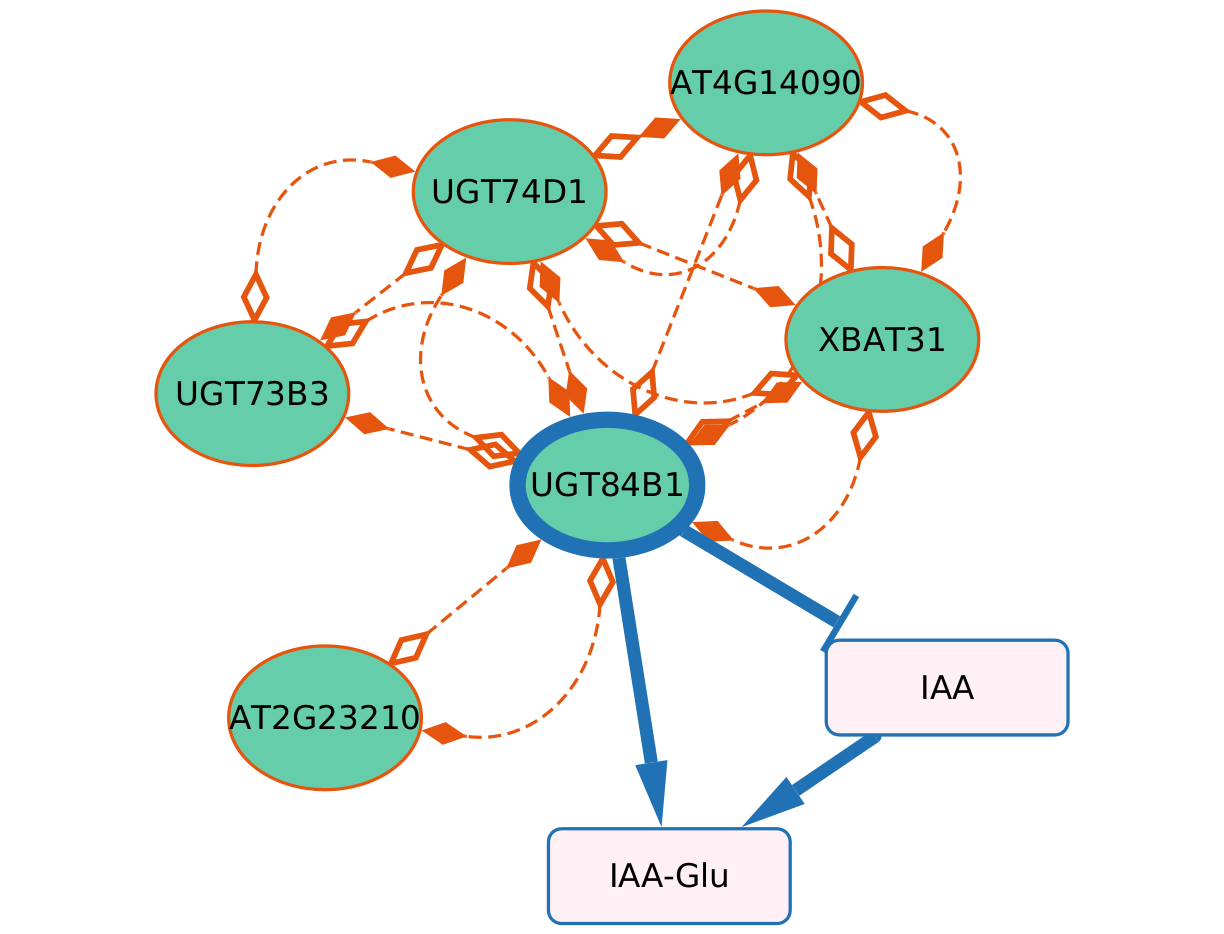

In [9]:
# ci-skip: needs a running Cytoscape

suid = show_augmented(sample, f"sample: {sample_node}", collection=collection)
Image(cu.export_network(output_dir / "augmented-sample.png", format="PNG", zoom=150, network=suid))

---
## Part two: what the augmentation introduced

The rank threshold applies here, in the analysis: CKN ranks go from 0 (curated, from PSS) to 4
(only predicted); `None` keeps all ranks.

In [10]:
MAX_RANK = 1

### Export A: new direct CKN edges between PSS pairs

PSS node pairs with a CKN edge between them, but no PSS edge, with the best rank of their CKN
edges and their direction:

In [11]:
export_a = find_new_direct_edges(augmented, pss, max_rank=MAX_RANK)
assert not any(pss.has_edge(u, v) or pss.has_edge(v, u) for u, v in zip(export_a.u, export_a.v))
assert (export_a["rank"] <= MAX_RANK).all()
export_a.to_csv(output_dir / "augment-export-a-direct-edges.tsv", sep="\t", index=False)
print(len(export_a), "new directly connected PSS pairs (rank <=", MAX_RANK, ")")
export_a.head(10)

740 new directly connected PSS pairs (rank <= 1 )


,u,v,rank,direction
0,AT1G01140,AT4G17615,1,both
1,AT1G01140,AT5G24270,1,both
2,AT1G01140,AT5G47100,1,both
3,AT1G01480,AT4G11280,1,both
4,AT1G02450,AT1G09415,1,both
5,AT1G02450,AT3G12250,1,both
6,AT1G02450,AT5G06950,1,both
7,AT1G02450,AT5G20570,1,both
8,AT1G02980,AT3G62980,1,both
9,AT1G02980,AT5G25350,1,both


### Export B: PSS pairs through exactly one CKN intermediate

PSS node pairs without a PSS edge, both linked to the same CKN node, with the rank of each step
(`path_rank` is the worse of the two). Directions are not considered. A pair can have several
intermediates:

In [12]:
export_b = find_new_intermediate_pairs(augmented, pss, max_rank=MAX_RANK)
assert (export_b.path_rank <= MAX_RANK).all()
export_b.to_csv(output_dir / "augment-export-b-one-intermediate.tsv", sep="\t", index=False)
n_pairs_b = len(export_b[["u", "v"]].drop_duplicates())
print(len(export_b), "pair and intermediate combinations,", n_pairs_b, "PSS pairs (rank <=", MAX_RANK, ")")
export_b.head(10)

3717 pair and intermediate combinations, 2042 PSS pairs (rank <= 1 )


,u,v,intermediate,rank_ux,rank_xv,path_rank
0,AT3G48090,Ca2+,AT5G66900,0,0,0
1,AT3G48090,TNL[fc00004],AT5G66900,0,0,0
2,Ca2+,NRG1.1-EDS1,AT5G66900,0,0,0
3,Ca2+,TNL[fc00004],AT5G66900,0,0,0
4,NRG1.1-EDS1,TNL[fc00004],AT5G66900,0,0,0
5,AT1G01360,AT1G01480,AT4G26080,1,1,1
6,AT1G01360,AT1G78290,AT4G26080,1,1,1
7,AT1G01360,AT2G20180,AT1G72770,1,1,1
8,AT1G01360,AT2G20180,AT4G26080,1,1,1
9,AT1G01360,AT2G36270,AT4G26080,1,1,1


CKN hubs connect many PSS pairs at once: the intermediates with the most pairs.

In [13]:
export_b.intermediate.value_counts().head()

intermediate
AT5G20730    191
AT5G37020    153
AT1G30330    139
AT1G19220    136
AT1G78300    119
Name: count, dtype: int64

### One example pair from each export

`extract_pair_subnetwork` takes the two nodes of a pair (`role` `focus`), the intermediate if
any (`intermediate`), and their PSS neighbours (`context`, here at most 10 each), with all edges
between them; the new CKN edges between the focus and intermediate nodes have `edge_status`
`new_from_ckn` (drawn wider). For export B we take the first pair of genes through a gene.

In [14]:
MAX_NEIGHBOURS = 10

row_a = export_a.iloc[0]
sub_a = extract_pair_subnetwork(augmented, pss, row_a.u, row_a.v, max_neighbours=MAX_NEIGHBOURS)
print(f"Export A pair: {row_a.u} - {row_a.v} (rank {row_a['rank']}, {row_a.direction}):", sub_a)

# the first pair of genes (not metabolites or complexes) through a gene
is_gene = r"AT[1-5CM]G\d{5}"
genes_only = export_b[export_b[["u", "v", "intermediate"]].apply(lambda col: col.str.fullmatch(is_gene)).all(axis=1)]
row_b = genes_only.iloc[0]
sub_b = extract_pair_subnetwork(augmented, pss, row_b.u, row_b.v, intermediate=row_b.intermediate,
                                max_neighbours=MAX_NEIGHBOURS)
print(f"Export B pair: {row_b.u} - {row_b.intermediate} - {row_b.v} (path rank {row_b.path_rank}):", sub_b)
assert sub_b.nodes[row_b.intermediate]["role"] == "intermediate"

Export A pair: AT1G01140 - AT4G17615 (rank 1, both): MultiDiGraph with 20 nodes and 76 edges
Export B pair: AT1G01360 - AT4G26080 - AT1G01480 (path rank 1): MultiDiGraph with 14 nodes and 53 edges


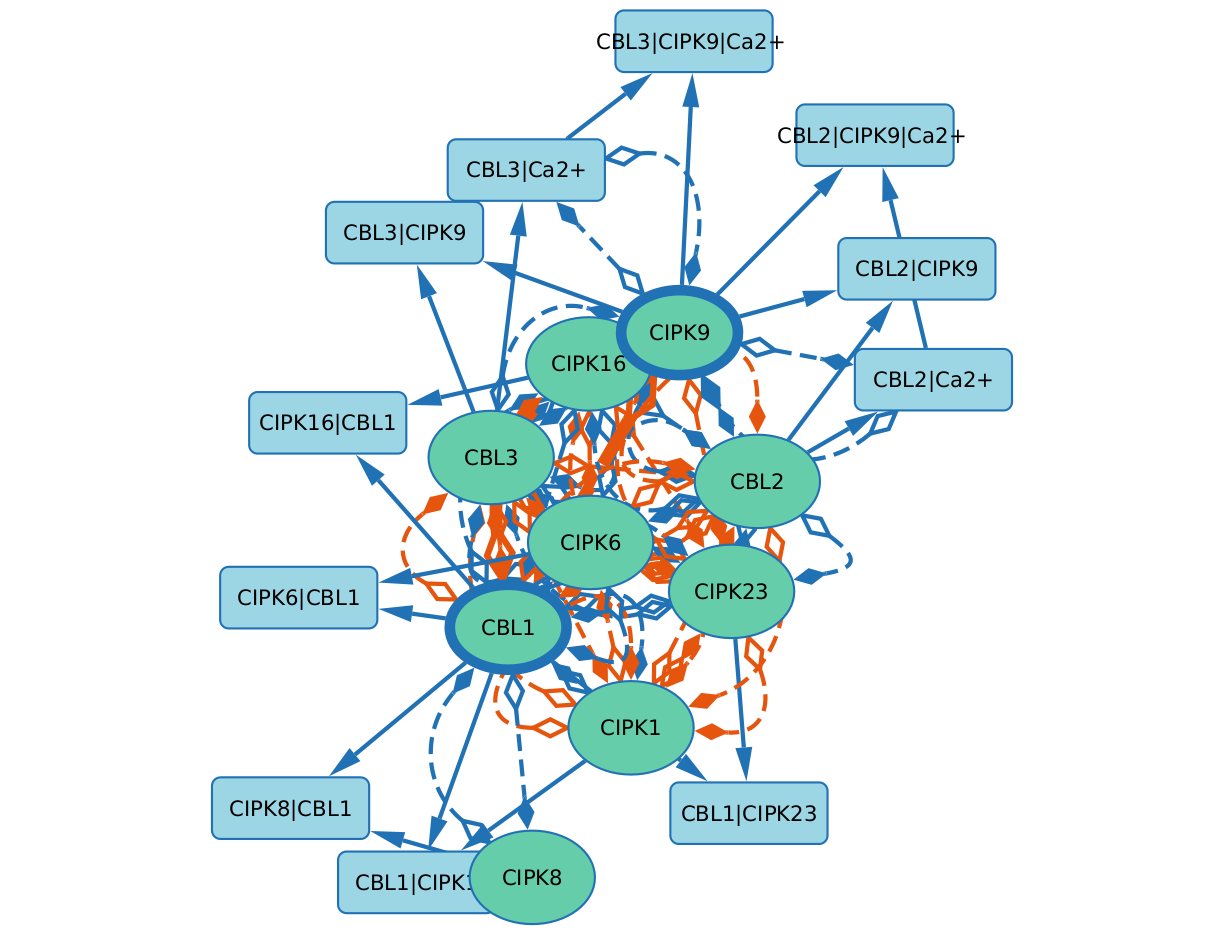

In [15]:
# ci-skip: needs a running Cytoscape

suid = show_augmented(sub_a, f"export A: {row_a.u}, {row_a.v}", collection=collection)
Image(cu.export_network(output_dir / "augment-export-a-pair.png", format="PNG", zoom=150, network=suid))

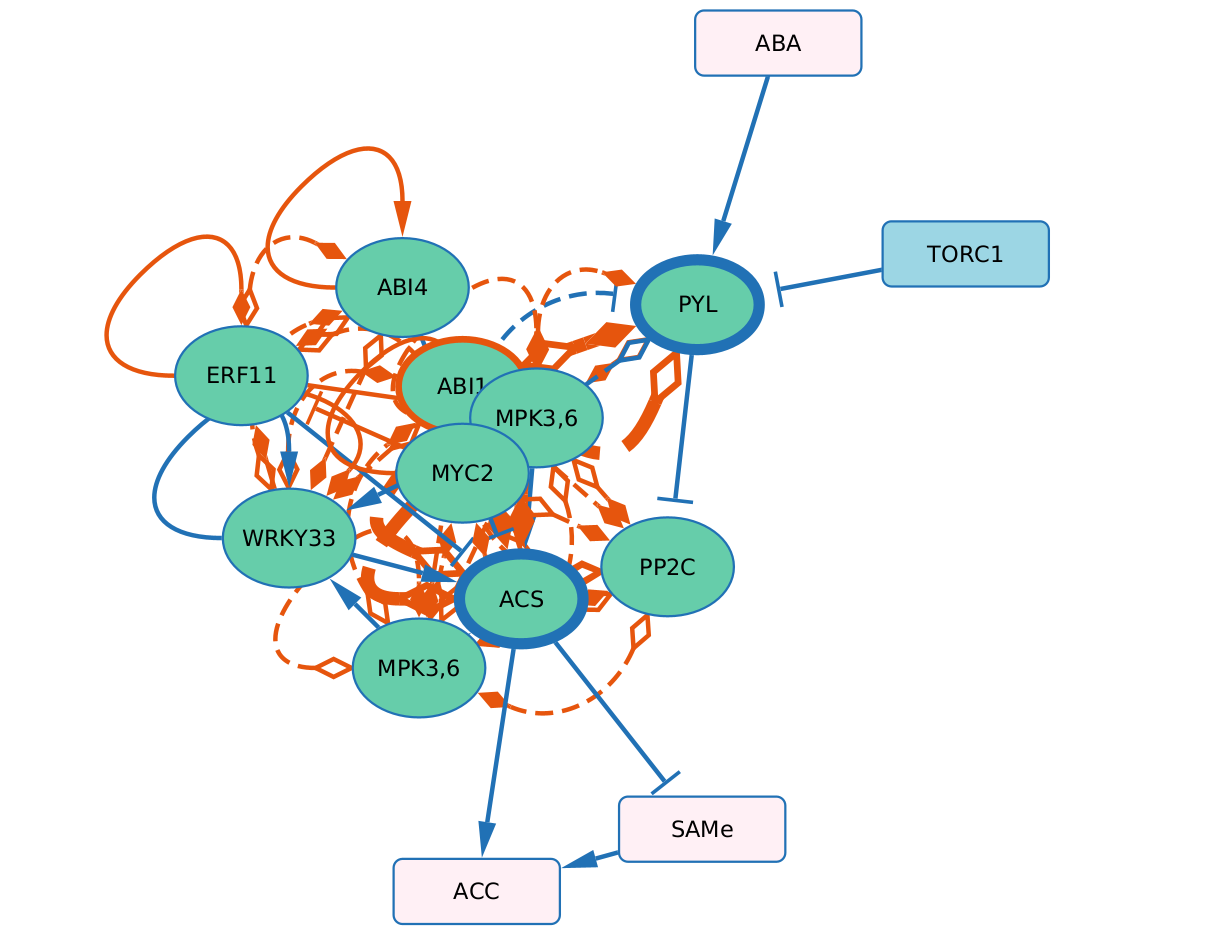

In [16]:
# ci-skip: needs a running Cytoscape

suid = show_augmented(sub_b, f"export B: {row_b.u}, {row_b.intermediate}, {row_b.v}", collection=collection)
Image(cu.export_network(output_dir / "augment-export-b-pair.png", format="PNG", zoom=150, network=suid))

---
## Part three: the neighbourhood of a node

Pick any node, random or chosen, and see how much CKN changed its neighbourhood.

**How large a neighbourhood?**

- **`radius=1`** (default, recommended): direct neighbours only. Did CKN change what this node
  is connected to? Always small enough to read.
- **`radius=2`**: neighbours of neighbours. Can show crosstalk through a CKN intermediate,
  but some CKN hubs connect hundreds of PSS pairs (export B), so it can get large: use it with
  `max_neighbours` (e.g. 15 to 25).
- **`radius` 3 or more** is not recommended for looking at one node; use the exports of part
  two instead.

In [17]:
NODE = None     # a node id (e.g. an AGI code), or None for a random one
ORIGIN = "PSS"  # for the random pick: "PSS", "CKN" or None (any)
SEED = 2        # for a reproducible random pick (None: a different one every time)
RADIUS = 1
MAX_NEIGHBOURS = 20

node = NODE or pick_random_node(augmented, origin=ORIGIN, seed=SEED)
print("Node:", node, "origin", augmented.nodes[node]["origin"])

Node: AT1G22400 origin PSS


In [18]:
stats = get_node_neighbourhood_augmentation(pss, augmented, node, radius=RADIUS,
                                            max_neighbours=MAX_NEIGHBOURS)
stats

{'node': 'AT1G22400',
 'radius': 1,
 'pss_neighbours': 9,
 'augmented_neighbours': 20,
 'ckn_added_neighbours': 12,
 'pct_new': 60.0}

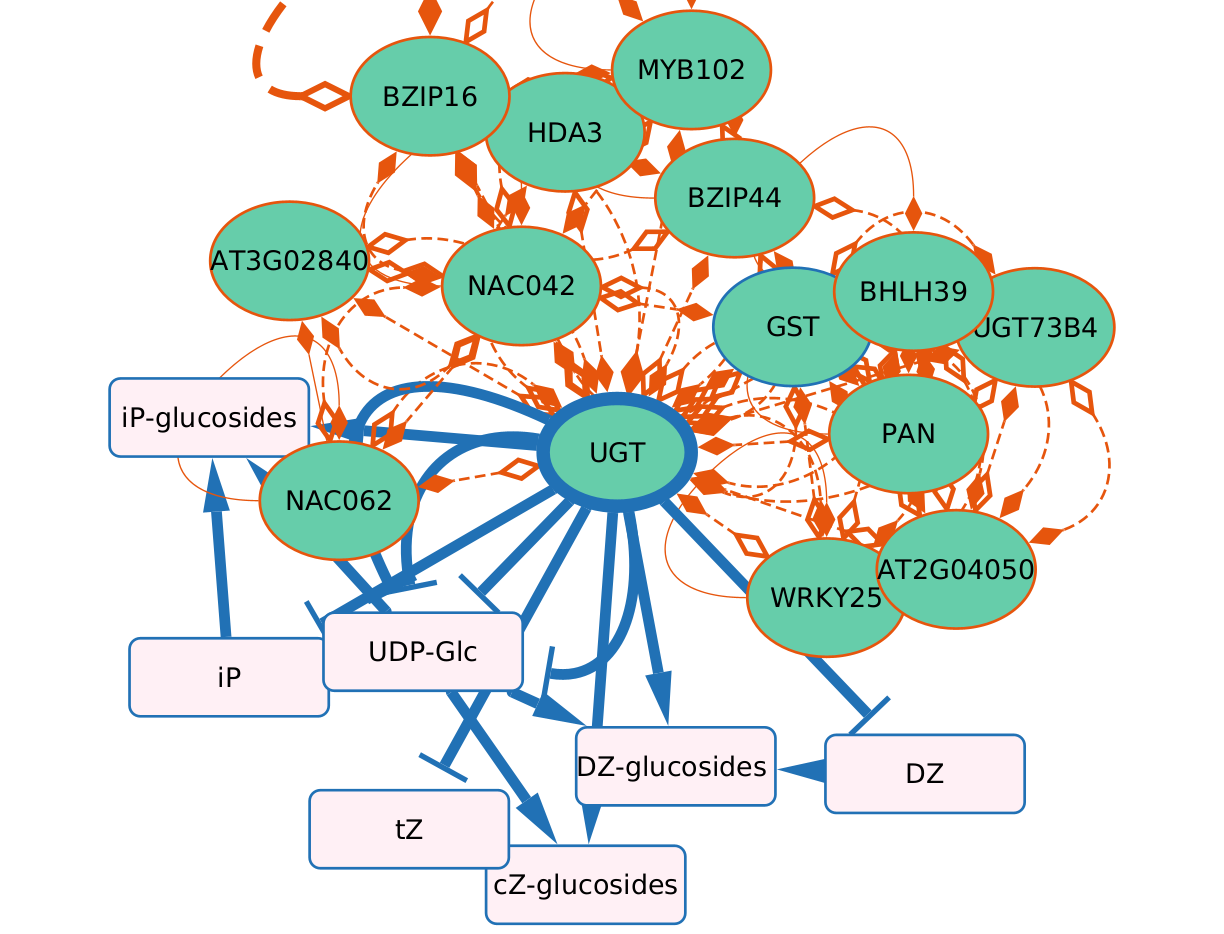

In [19]:
# ci-skip: needs a running Cytoscape

neighbourhood = extract_node_neighbourhood(augmented, node, radius=RADIUS, max_neighbours=MAX_NEIGHBOURS)
suid = show_augmented(neighbourhood, f"neighbourhood: {node}, radius {RADIUS}", collection=collection)
Image(cu.export_network(output_dir / "augment-neighbourhood.png", format="PNG", zoom=150, network=suid))

---
## Part four: augment your own network

`build_augmented_pss` takes any networkx graph as `pss`: also a small network of the genes you
are interested in, made by hand or e.g. selected in Cytoscape. Here one node is a mistyped gene
id, in neither PSS nor CKN; `check_unaugmented_nodes` finds it.

In [20]:
custom = nx.MultiDiGraph()
custom.add_edge("AT5G12080", "AT3G02090")
custom.add_node("NOT_A_REAL_GENE_ID")      # e.g. a typo

custom_augmented = build_augmented_pss(custom, ckn)
unaugmented_custom = check_unaugmented_nodes(custom, custom_augmented)
assert "NOT_A_REAL_GENE_ID" in unaugmented_custom
print("Got no CKN edge:", unaugmented_custom)
get_augmentation_summary(custom, custom_augmented)

INFO skm_tools.augment_pss: Augmented PSS (3 nodes, 1 edges) with 150 CKN nodes and 2648 CKN edges (300 touching PSS, 2348 between added CKN nodes); 1 PSS nodes got no CKN edge.


Got no CKN edge: {'NOT_A_REAL_GENE_ID'}


{'pss_nodes': 3,
 'pss_edges': 1,
 'augmented_nodes': 153,
 'augmented_edges': 2649,
 'ckn_nodes_added': 150,
 'ckn_edges_added': 2648}

The part two and three functions work the same on it:

In [21]:
custom_a = find_new_direct_edges(custom_augmented, custom)
custom_b = find_new_intermediate_pairs(custom_augmented, custom)
print(len(custom_a), "new direct pairs,", len(custom_b), "pair and intermediate combinations")
get_node_neighbourhood_augmentation(custom, custom_augmented, "AT5G12080")

0 new direct pairs, 0 pair and intermediate combinations


{'node': 'AT5G12080',
 'radius': 1,
 'pss_neighbours': 1,
 'augmented_neighbours': 12,
 'ckn_added_neighbours': 11,
 'pct_new': 91.66666666666667}

---
## Summary

In [22]:
print(f"""Augmented network: {summary['augmented_nodes']:,} nodes ({summary['pss_nodes']:,} PSS + {summary['ckn_nodes_added']:,} CKN),
  {summary['augmented_edges']:,} edges ({summary['pss_edges']:,} PSS + {summary['ckn_edges_added']:,} CKN)
Export A (rank <= {MAX_RANK}): {len(export_a):,} new directly connected PSS pairs
Export B (rank <= {MAX_RANK}): {len(export_b):,} pair and intermediate combinations, {n_pairs_b:,} PSS pairs
Node {stats['node']}: {stats['ckn_added_neighbours']} of its {stats['augmented_neighbours']} neighbours are from CKN ({stats['pct_new']:.0f}%)""")

Augmented network: 12,978 nodes (1,067 PSS + 11,911 CKN),
  714,966 edges (4,397 PSS + 710,569 CKN)
Export A (rank <= 1): 740 new directly connected PSS pairs
Export B (rank <= 1): 3,717 pair and intermediate combinations, 2,042 PSS pairs
Node AT1G22400: 12 of its 20 neighbours are from CKN (60%)
